In [ ]:
!nvidia-smi
!df -h /content

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/nimbus

Mounted at /content/drive


In [ ]:
!pip -q install gdown
%cd /content
!gdown 1-fSKYsKr5wuYuXJE2CDX_Yfr4Ylwjfqm -O lsssdd.zip
!ls -lh lsssdd.zip

/content
Downloading...
From (original): https://drive.google.com/uc?id=1-fSKYsKr5wuYuXJE2CDX_Yfr4Ylwjfqm
From (redirected): https://drive.google.com/uc?id=1-fSKYsKr5wuYuXJE2CDX_Yfr4Ylwjfqm&confirm=t&uuid=ce2ab2b6-eb62-48ed-8744-7047a00e0fc7
To: /content/lsssdd.zip
100% 8.33G/8.33G [01:50<00:00, 75.1MB/s]
-rw-r--r-- 1 root root 7.8G Sep  6  2020 lsssdd.zip


In [ ]:
!unzip -l lsssdd.zip | awk '{print $4}' | grep -E "/$" | head -20

LS-SSDD-v1.0-OPEN/
LS-SSDD-v1.0-OPEN/Annotations/
LS-SSDD-v1.0-OPEN/Annotations_sub/
LS-SSDD-v1.0-OPEN/ImageSets/
LS-SSDD-v1.0-OPEN/ImageSets/Layout/
LS-SSDD-v1.0-OPEN/ImageSets/Main/
LS-SSDD-v1.0-OPEN/JPEGImages/
LS-SSDD-v1.0-OPEN/JPEGImages_sub/
LS-SSDD-v1.0-OPEN/JPEGImages_VH/
LS-SSDD-v1.0-OPEN/Tools/


In [ ]:
!unzip -l lsssdd.zip | grep -c "JPEGImages_sub/.*\.jpg"

9000


In [ ]:
!unzip -l lsssdd.zip | grep -c "Annotations_sub/.*\.xml"

9000


In [ ]:
!unzip -q -o lsssdd.zip "*JPEGImages_sub/*" "*Annotations_sub/*" -d /content/lsssdd

In [ ]:
!find /content/lsssdd -name "*.jpg" | wc -l

9000


In [ ]:
!find /content/lsssdd -name "*.jpg" | head -5

/content/lsssdd/LS-SSDD-v1.0-OPEN/JPEGImages_sub/14_20_22.jpg
/content/lsssdd/LS-SSDD-v1.0-OPEN/JPEGImages_sub/02_5_19.jpg
/content/lsssdd/LS-SSDD-v1.0-OPEN/JPEGImages_sub/11_15_28.jpg
/content/lsssdd/LS-SSDD-v1.0-OPEN/JPEGImages_sub/12_10_17.jpg
/content/lsssdd/LS-SSDD-v1.0-OPEN/JPEGImages_sub/06_19_5.jpg


In [ ]:
import glob, os
import xml.etree.ElementTree as ET
import pandas as pd

rows = []
for xml_path in glob.glob('/content/lsssdd/**/Annotations_sub/*.xml', recursive=True):
    root = ET.parse(xml_path).getroot()
    stem = os.path.splitext(os.path.basename(xml_path))[0]
    objs = root.findall('object')
    if not objs:
        rows.append({'image': stem, 'xmin': None, 'ymin': None, 'xmax': None, 'ymax': None})
    for obj in objs:
        b = obj.find('bndbox')
        rows.append({'image': stem, **{k: int(float(b.find(k).text))
                                       for k in ['xmin', 'ymin', 'xmax', 'ymax']}})

df = pd.DataFrame(rows)
df['scene'] = df['image'].str.split('_').str[0].astype(int)
df.to_csv('/content/drive/MyDrive/nimbus/lsssdd_boxes.csv', index=False)

print(df['image'].nunique(), 'images |', df['xmin'].notna().sum(), 'ships')
print(df.groupby('scene')['xmin'].count())

9000 images | 6015 ships
scene
1     536
2     344
3     233
4     421
5     282
6     270
7     467
8     307
9     352
10    425
11    746
12    760
13    273
14    351
15    248
Name: xmin, dtype: int64


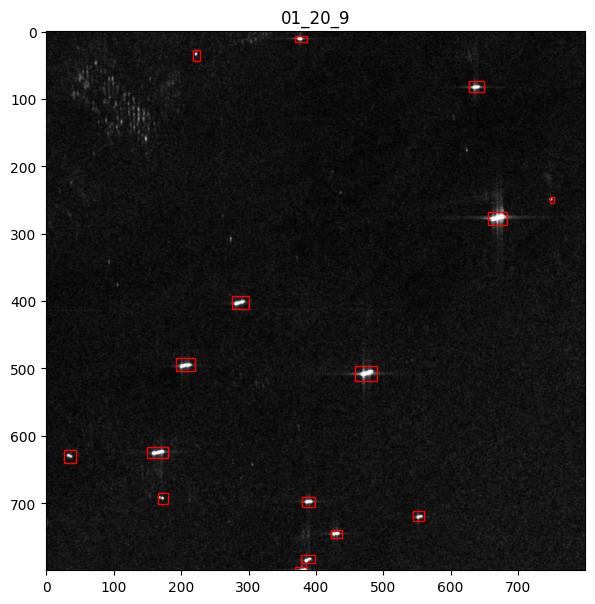

In [ ]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

IMG_DIR = glob.glob('/content/lsssdd/**/JPEGImages_sub', recursive=True)[0]
sample = df.dropna().iloc[0]['image']
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(Image.open(f'{IMG_DIR}/{sample}.jpg'), cmap='gray')
for _, r in df[df.image == sample].dropna().iterrows():
    ax.add_patch(patches.Rectangle((r.xmin, r.ymin), r.xmax - r.xmin, r.ymax - r.ymin,
                                   fill=False, edgecolor='red', linewidth=1))
ax.set_title(sample); plt.show()

In [ ]:
import numpy as np
from scipy import ndimage as ndi
from tqdm.auto import tqdm

CHIP, H = 64, 32
rng = np.random.default_rng(0)

def proposals(img, k=3.0, guard=5, train=15, min_px=3):
    """Simple CA-CFAR-style bright-spot finder (same idea as Nimbus's detector)."""
    img = img.astype(np.float32)
    big = ndi.uniform_filter(img, 2*train+1) * (2*train+1)**2
    small = ndi.uniform_filter(img, 2*guard+1) * (2*guard+1)**2
    bg = (big - small) / ((2*train+1)**2 - (2*guard+1)**2)
    mask = img > k * np.maximum(bg, 1.0)
    lab, n = ndi.label(mask)
    if n == 0:
        return []
    idx = range(1, n + 1)
    sizes = ndi.sum(mask, lab, idx)
    cents = ndi.center_of_mass(mask, lab, idx)
    return [(int(r), int(c)) for (r, c), s in zip(cents, sizes) if s >= min_px]

def crop(img, r, c):
    return np.pad(img, H, mode='reflect')[r:r+CHIP, c:c+CHIP]

def near_box(r, c, boxes, pad):
    return any(b.xmin-pad <= c <= b.xmax+pad and b.ymin-pad <= r <= b.ymax+pad
               for b in boxes.itertuples())

X, y, scene, kind = [], [], [], []
for name, g in tqdm(df.groupby('image')):
    img = np.array(Image.open(f'{IMG_DIR}/{name}.jpg').convert('L'))
    s = int(g['scene'].iloc[0])
    boxes = g.dropna(subset=['xmin'])

    for b in boxes.itertuples():
        X.append(crop(img, int((b.ymin+b.ymax)//2), int((b.xmin+b.xmax)//2)))
        y.append(1); scene.append(s); kind.append('ship')

    fps = [p for p in proposals(img) if not near_box(*p, boxes, pad=4)]
    if len(fps) > 5:
        fps = [fps[i] for i in rng.choice(len(fps), 5, replace=False)]
    for r, c in fps:
        X.append(crop(img, r, c)); y.append(0); scene.append(s); kind.append('cfar_fp')

    for _ in range(2 if len(boxes) else 4):
        r, c = int(rng.integers(0, img.shape[0])), int(rng.integers(0, img.shape[1]))
        if not near_box(r, c, boxes, pad=CHIP):
            X.append(crop(img, r, c)); y.append(0); scene.append(s); kind.append('background')

X = np.stack(X).astype(np.uint8)
y, scene, kind = np.array(y), np.array(scene), np.array(kind)
np.savez_compressed('/content/drive/MyDrive/nimbus/chips.npz', X=X, y=y, scene=scene, kind=kind)
print(X.shape)
print(pd.Series(kind).value_counts())

  0%|          | 0/9000 [00:00<?, ?it/s]

In [ ]:
!nvidia-smi

Sun Nov  8 00:45:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/nimbus/

Mounted at /content/drive
lsssdd_boxes.csv


In [ ]:
!pip -q install gdown
%cd /content
!gdown 1-fSKYsKr5wuYuXJE2CDX_Yfr4Ylwjfqm -O lsssdd.zip
!unzip -q -o lsssdd.zip "*JPEGImages_sub/*" "*Annotations_sub/*" -d /content/lsssdd
!find /content/lsssdd -name "*.jpg" | wc -l

/content
Downloading...
From (original): https://drive.google.com/uc?id=1-fSKYsKr5wuYuXJE2CDX_Yfr4Ylwjfqm
From (redirected): https://drive.google.com/uc?id=1-fSKYsKr5wuYuXJE2CDX_Yfr4Ylwjfqm&confirm=t&uuid=28f7fb38-458f-41bf-b30b-f2913fb4374c
To: /content/lsssdd.zip
100% 8.33G/8.33G [00:57<00:00, 145MB/s]


In [9]:
import glob
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage as ndi
from tqdm.auto import tqdm

df = pd.read_csv('/content/drive/MyDrive/nimbus/lsssdd_boxes.csv')
IMG_DIR = glob.glob('/content/lsssdd/**/JPEGImages_sub', recursive=True)[0]
print(df['image'].nunique(), 'images |', df['xmin'].notna().sum(), 'ships')

CHIP, H = 64, 32
rng = np.random.default_rng(0)

def proposals(img, k=3.0, guard=5, train=15, min_px=3):
    """Simple CA-CFAR-style bright-spot finder (same idea as Nimbus's detector)."""
    img = img.astype(np.float32)
    big = ndi.uniform_filter(img, 2*train+1) * (2*train+1)**2
    small = ndi.uniform_filter(img, 2*guard+1) * (2*guard+1)**2
    bg = (big - small) / ((2*train+1)**2 - (2*guard+1)**2)
    mask = img > k * np.maximum(bg, 1.0)
    lab, n = ndi.label(mask)
    if n == 0:
        return []
    idx = range(1, n + 1)
    sizes = ndi.sum(mask, lab, idx)
    cents = ndi.center_of_mass(mask, lab, idx)
    return [(int(r), int(c)) for (r, c), s in zip(cents, sizes) if s >= min_px]

def crop(padded, r, c):
    # .copy() so each chip owns its 4 KB instead of pinning the whole padded image
    return padded[r:r+CHIP, c:c+CHIP].copy()

def near_box(r, c, boxes, pad):
    return any(b.xmin-pad <= c <= b.xmax+pad and b.ymin-pad <= r <= b.ymax+pad
               for b in boxes.itertuples())

def valid_chip(ch):
    return (ch <= 8).mean() < 0.05   # JPEG no-data borders are ~0, allow a little compression noise

X, y, scene, kind = [], [], [], []
for name, g in tqdm(df.groupby('image')):
    img = np.array(Image.open(f'{IMG_DIR}/{name}.jpg').convert('L'))
    padded = np.pad(img, H, mode='reflect')
    s = int(g['scene'].iloc[0])
    boxes = g.dropna(subset=['xmin'])

    def add(r, c, label, k):
        ch = crop(padded, r, c)
        if valid_chip(ch):
            X.append(ch); y.append(label); scene.append(s); kind.append(k)

    for b in boxes.itertuples():
        add(int((b.ymin+b.ymax)//2), int((b.xmin+b.xmax)//2), 1, 'ship')

    fps = [p for p in proposals(img) if not near_box(*p, boxes, pad=4)]
    fps = [p for p in fps if valid_chip(crop(padded, *p))]          # filter BEFORE sampling 5
    if len(fps) > 5:
        fps = [fps[i] for i in rng.choice(len(fps), 5, replace=False)]
    for r, c in fps:
        add(r, c, 0, 'cfar_fp')

    for _ in range(2 if len(boxes) else 4):
        r, c = int(rng.integers(0, img.shape[0])), int(rng.integers(0, img.shape[1]))
        if not near_box(r, c, boxes, pad=CHIP):
            add(r, c, 0, 'background')

X = np.stack(X).astype(np.uint8)
y, scene, kind = np.array(y), np.array(scene), np.array(kind)
np.savez_compressed('/content/drive/MyDrive/nimbus/chips.npz', X=X, y=y, scene=scene, kind=kind)
print(X.shape, f'{X.nbytes / 1e6:.0f} MB')
print(pd.Series(kind).value_counts())

9000 images | 6015 ships


  0%|          | 0/9000 [00:00<?, ?it/s]

(42505, 64, 64) 174 MB
background    28999
cfar_fp        7673
ship           5833
Name: count, dtype: int64


In [10]:
import numpy as np, pandas as pd
import torch, torch.nn as nn, torchvision
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import average_precision_score, precision_score, recall_score

OUT = '/content/drive/MyDrive/nimbus'
d = np.load(f'{OUT}/chips.npz')
X, y, scene, kind = d['X'], d['y'], d['scene'], d['kind']

tr, va, te = scene <= 9, scene == 10, scene >= 11
for nm, m in [('train (scenes 1-9)', tr), ('val (scene 10)', va), ('test (scenes 11-15)', te)]:
    print(f'{nm:22s} {m.sum():6d} chips, {y[m].sum():5d} ships')

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
Xt = torch.tensor(X).float().div(255).unsqueeze(1)
yt = torch.tensor(y).float()
MEAN, STD = Xt[tr].mean().item(), Xt[tr].std().item()

class ShipClassifier(nn.Module):
    """Input: (N,1,64,64) in [0,1]. Output: logit that the chip is a ship."""
    def __init__(self, mean=0.0, std=1.0):
        super().__init__()
        self.net = torchvision.models.resnet18(weights='IMAGENET1K_V1')
        self.net.fc = nn.Linear(512, 1)
        self.register_buffer('mean', torch.tensor(mean, dtype=torch.float32))
        self.register_buffer('std', torch.tensor(std, dtype=torch.float32))
    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.net(x.repeat(1, 3, 1, 1)).squeeze(1)

def augment(x):
    if torch.rand(1) < .5: x = x.flip(3)
    if torch.rand(1) < .5: x = x.flip(2)
    return torch.rot90(x, int(torch.randint(0, 4, (1,))), (2, 3))

def predict(model, mask):
    model.eval(); out = []
    with torch.no_grad():
        for (xb,) in DataLoader(TensorDataset(Xt[mask]), batch_size=1024):
            out.append(torch.sigmoid(model(xb.to(dev))).cpu())
    return torch.cat(out).numpy()

model = ShipClassifier(MEAN, STD).to(dev)
pos_weight = torch.tensor(float((y[tr] == 0).sum() / (y[tr] == 1).sum()),
                          dtype=torch.float32, device=dev)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
loader = DataLoader(TensorDataset(Xt[tr], yt[tr]), batch_size=256, shuffle=True)

best_ap = 0
for epoch in range(8):
    model.train(); total = 0
    for xb, yb in loader:
        xb, yb = augment(xb.to(dev)), yb.to(dev)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * len(xb)
    ap = average_precision_score(y[va], predict(model, va))
    print(f'epoch {epoch+1}  train loss {total / tr.sum():.3f}  val AP {ap:.3f}')
    if ap > best_ap:
        best_ap = ap
        torch.save({'state_dict': model.state_dict(), 'mean': MEAN, 'std': STD},
                   f'{OUT}/ship_clf_best.pt')
print('best val AP', round(best_ap, 3))

train (scenes 1-9)      25687 chips,  3138 ships
val (scene 10)           2506 chips,   423 ships
test (scenes 11-15)     14312 chips,  2272 ships
epoch 1  train loss 0.367  val AP 0.922
epoch 2  train loss 0.200  val AP 0.892
epoch 3  train loss 0.180  val AP 0.946
epoch 4  train loss 0.163  val AP 0.958
epoch 5  train loss 0.150  val AP 0.965
epoch 6  train loss 0.142  val AP 0.970
epoch 7  train loss 0.143  val AP 0.960
epoch 8  train loss 0.129  val AP 0.978
best val AP 0.978


In [11]:
ckpt = torch.load(f'{OUT}/ship_clf_best.pt')
model = ShipClassifier(ckpt['mean'], ckpt['std']).to(dev)
model.load_state_dict(ckpt['state_dict'])

p = predict(model, te)
pred = (p >= 0.5).astype(int)
k = kind[te]
print(f'Test AP {average_precision_score(y[te], p):.3f} | '
      f'precision {precision_score(y[te], pred):.3f} | recall {recall_score(y[te], pred):.3f}')
print(f"Ships kept:                 {pred[k == 'ship'].mean():.1%}")
print(f"CFAR false alarms rejected: {1 - pred[k == 'cfar_fp'].mean():.1%}")
print(f"Background rejected:        {1 - pred[k == 'background'].mean():.1%}")

Test AP 0.981 | precision 0.804 | recall 0.980
Ships kept:                 98.0%
CFAR false alarms rejected: 82.1%
Background rejected:        99.2%


In [12]:
from sklearn.metrics import precision_recall_curve
pv = predict(model, va)
prec, rec, thr = precision_recall_curve(y[va], pv)
i = np.where(rec[:-1] >= 0.95)[0][-1]      # highest threshold that still keeps 95% of val ships
T = float(thr[i])

pred_t = (p >= T).astype(int)
print(f'Threshold {T:.3f} (chosen on scene 10, not the test set)')
print(f'Test precision {precision_score(y[te], pred_t):.3f} | recall {recall_score(y[te], pred_t):.3f}')
print(f"Ships kept:                 {pred_t[k == 'ship'].mean():.1%}")
print(f"CFAR false alarms rejected: {1 - pred_t[k == 'cfar_fp'].mean():.1%}")
print(f"Background rejected:        {1 - pred_t[k == 'background'].mean():.1%}")

import json
json.dump({'threshold': T, 'val_target_recall': 0.95},
          open(f'{OUT}/ship_clf_threshold.json', 'w'))

Threshold 0.784 (chosen on scene 10, not the test set)
Test precision 0.864 | recall 0.968
Ships kept:                 96.8%
CFAR false alarms rejected: 88.6%
Background rejected:        99.5%


In [13]:
!pip -q install onnx onnxscript onnxruntime

import onnxruntime as ort
model.eval().cpu()
dummy = torch.zeros(1, 1, 64, 64)
torch.onnx.export(model, dummy, f'{OUT}/ship_clf.onnx',
                  input_names=['chip'], output_names=['logit'],
                  dynamic_axes={'chip': {0: 'n'}, 'logit': {0: 'n'}})

# verify the exported model gives the same answers as PyTorch
sess = ort.InferenceSession(f'{OUT}/ship_clf.onnx')
sample = Xt[te][:64]
onnx_out = sess.run(None, {'chip': sample.numpy()})[0]
with torch.no_grad():
    torch_out = model(sample).numpy()
print('max difference:', float(np.abs(onnx_out - torch_out).max()))
!ls -lh {OUT}/ship_clf.onnx

/tmp/ipykernel_1158/215940235.py:6: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(model, dummy, f'{OUT}/ship_clf.onnx',


[torch.onnx] Obtain model graph for `ShipClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ShipClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
max difference: 5.9604644775390625e-06
-rw------- 1 root root 102K Nov  8 01:22 /content/drive/MyDrive/nimbus/ship_clf.onnx


In [14]:
import onnx, onnxruntime as ort
m = onnx.load(f'{OUT}/ship_clf.onnx')            # pulls in the external weights
onnx.save_model(m, f'{OUT}/ship_clf_single.onnx', save_as_external_data=False)
!ls -lh {OUT}

sess = ort.InferenceSession(f'{OUT}/ship_clf_single.onnx')
print('max difference:', float(np.abs(sess.run(None, {'chip': Xt[te][:64].numpy()})[0]
                                      - model.cpu()(Xt[te][:64]).detach().numpy()).max()))

total 256M
-rw------- 1 root root 127M Nov  8 01:17 chips.npz
-rw------- 1 root root 231K Nov  8 01:02 examples.png
-rw------- 1 root root 304K Nov  8 00:40 lsssdd_boxes.csv
-rw------- 1 root root  43M Nov  8 01:20 ship_clf_best.pt
-rw------- 1 root root 102K Nov  8 01:22 ship_clf.onnx
-rw------- 1 root root  43M Nov  8 01:22 ship_clf.onnx.data
-rw------- 1 root root  43M Nov  8 01:23 ship_clf_single.onnx
-rw------- 1 root root   60 Nov  8 01:22 ship_clf_threshold.json
max difference: 5.9604644775390625e-06


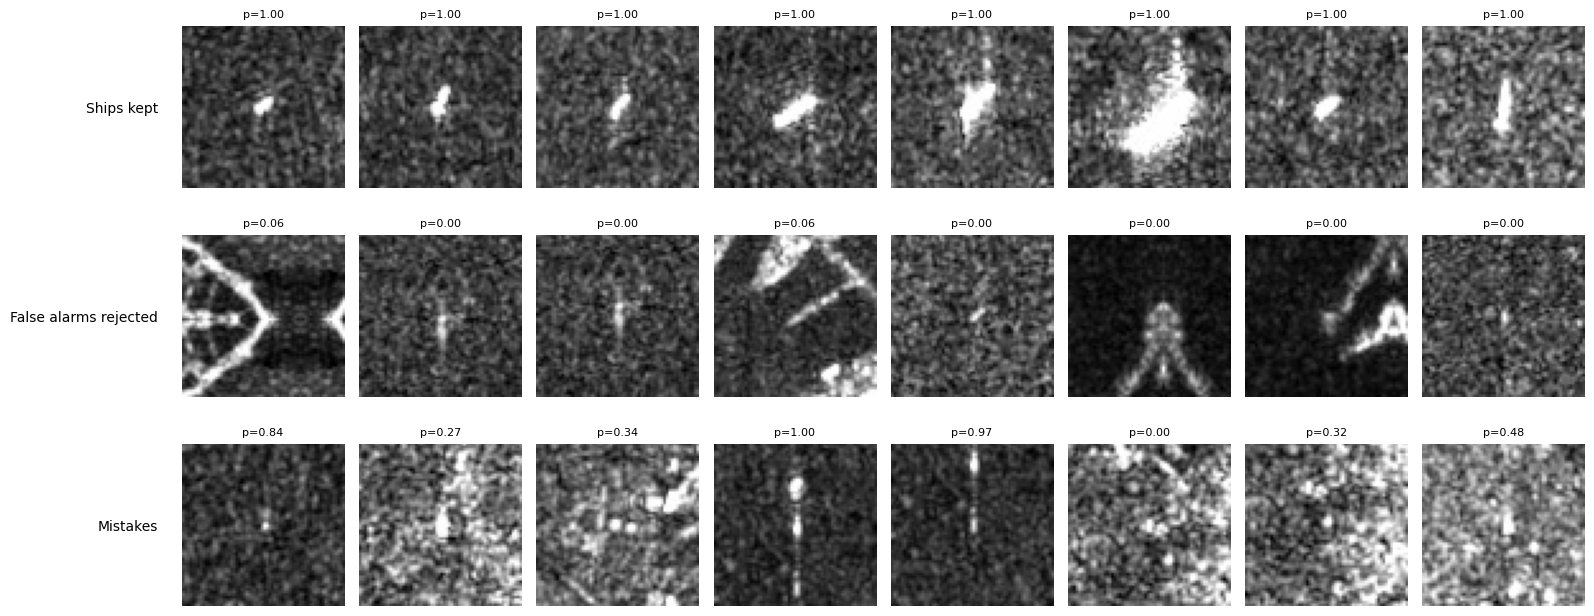

In [15]:
import matplotlib.pyplot as plt
model.to(dev)
groups = [('Ships kept', (k == 'ship') & (pred == 1)),
          ('False alarms rejected', (k == 'cfar_fp') & (pred == 0)),
          ('Mistakes', pred != y[te])]
Xte = X[te]
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for row, (title, mask) in enumerate(groups):
    idx = np.where(mask)[0][:8]
    for col in range(8):
        ax = axes[row, col]; ax.axis('off')
        if col < len(idx):
            ax.imshow(Xte[idx[col]], cmap='gray')
            ax.set_title(f'p={p[idx[col]]:.2f}', fontsize=8)
    axes[row, 0].text(-10, 32, title, ha='right', va='center', fontsize=10)
plt.tight_layout()
plt.savefig(f'{OUT}/examples.png', dpi=150, bbox_inches='tight'); plt.show()

In [17]:
!unzip -o -q lsssdd.zip "*Tools/*" -d /content/lsssdd
!ls /content/lsssdd/LS-SSDD-v1.0-OPEN/Tools

image_stitch.py  user_manual.pdf


In [18]:
!pip -q install planetary-computer pystac-client rasterio onnxruntime

import json, numpy as np, rasterio, pystac_client, planetary_computer
from rasterio.windows import Window, from_bounds
from rasterio.warp import transform_bounds

OUT = '/content/drive/MyDrive/nimbus'
SCENE = 'S1D_IW_GRDH_1SDV_20261102T052330_20261102T052402_005284_00A0D2_rtc'
BBOX = (11.45, 56.60, 12.30, 57.20)   # same chip as the repo's demo

cat = pystac_client.Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',
                                modifier=planetary_computer.sign_inplace)
item = next(cat.search(collections=['sentinel-1-rtc'], ids=[SCENE]).items())
with rasterio.open(item.assets['vv'].href) as src:
    sb = transform_bounds('EPSG:4326', src.crs, *BBOX, densify_pts=21)
    win = from_bounds(*sb, transform=src.transform).intersection(Window(0, 0, src.width, src.height))
    vv = src.read(1, window=win).astype(np.float32)
    TR, CRS, NODATA, RES = src.window_transform(win), src.crs, src.nodata, src.res

print('read', vv.shape, CRS, 'pixel size', RES, 'nodata', NODATA)
np.save('/content/kattegat_vv_native.npy', vv)   # local copy in case you rerun scoring

read (6911, 5479) EPSG:32633 pixel size (10.0, 10.0) nodata -32768.0


In [20]:
import os, shutil
from google.colab import files

os.makedirs(f'{OUT}/kattegat', exist_ok=True)
up = files.upload()                       # a file picker appears: choose data/demo/matches.json from your repo
for name in up:
    shutil.move(name, f'{OUT}/kattegat/matches.json')
print(os.listdir(f'{OUT}/kattegat'))

Saving matches.json to matches.json
['matches.json']


pixel positions inside scene: True

id    AIS       name                   peak dB shore km  p(ship)  verdict
D001  matched   MILLERNTOR                32.3      7.0    1.000  vessel-like
D002  UNMATCHED -                         31.7     13.4    1.000  vessel-like
D003  matched   STAVROLIT                 31.5     16.1    1.000  vessel-like
D004  matched   VOLGABORG                 31.2     33.6    1.000  vessel-like
D005  matched   NAVIOS AVIOR              29.7      9.6    1.000  vessel-like
D006  matched   AS CLAUDIA                28.1     16.9    1.000  vessel-like
D007  matched   NOMAD                     25.0     32.0    1.000  vessel-like
D008  matched   BALLATA                   24.8     34.4    1.000  vessel-like
D009  matched   MEHMET KAHVECI A          24.4     10.9    1.000  vessel-like
D010  matched   BALKAN DERIN FEYZA        24.1     14.9    1.000  vessel-like
D011  matched   EXCELLER                  23.2     12.9    1.000  vessel-like
D012  matched   BALTIC SKIPPER  

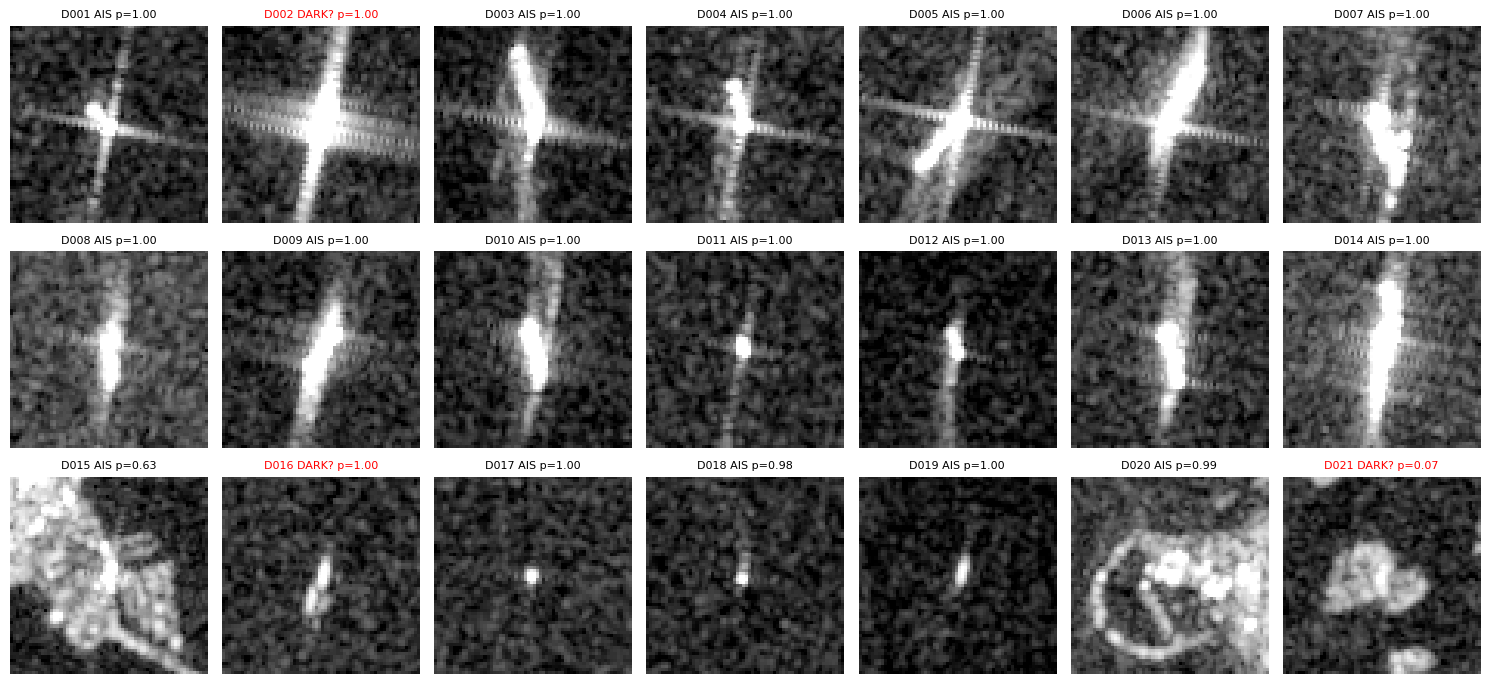

In [22]:
vv = np.load('/content/kattegat_vv_native.npy')

import onnxruntime as ort, matplotlib.pyplot as plt
from rasterio.warp import transform as warp_transform
from rasterio.transform import rowcol

dets = json.load(open(f'{OUT}/kattegat/matches.json'))
T = json.load(open(f'{OUT}/ship_clf_threshold.json'))['threshold']

valid = np.isfinite(vv) & (vv > 0)
if NODATA is not None:
    valid &= vv != NODATA
db = np.where(valid, 10 * np.log10(np.maximum(vv, 1e-6)), np.nan)

xs, ys = warp_transform('EPSG:4326', CRS, [d['lon'] for d in dets], [d['lat'] for d in dets])
rows, cols = rowcol(TR, xs, ys)
pos = list(zip(rows, cols))
print('pixel positions inside scene:',
      all(0 <= r < vv.shape[0] and 0 <= c < vv.shape[1] for r, c in pos))

# Match brightness to LS-SSDD using the local sea around the detections
ring = []
for r, c in pos:
    w = db[max(r-32, 0):r+32, max(c-32, 0):c+32].copy()
    w[w.shape[0]//2-8:w.shape[0]//2+8, w.shape[1]//2-8:w.shape[1]//2+8] = np.nan
    ring.append(w[np.isfinite(w)])
src50, src99 = np.percentile(np.concatenate(ring), [50, 99])

chips = np.load(f'{OUT}/chips.npz')
bg = chips['X'][chips['kind'] == 'background'][:3000].astype(np.float32)
ref50, ref99 = np.percentile(bg, [50, 99])

img8 = ref50 + (db - src50) * (ref99 - ref50) / (src99 - src50)
img8 = np.clip(np.nan_to_num(img8, nan=0), 0, 255).astype(np.uint8)
padded = np.pad(img8, 32, mode='reflect')
batch = np.stack([padded[r:r+64, c:c+64] for r, c in pos])

sess = ort.InferenceSession(f'{OUT}/ship_clf_single.onnx')
logits = sess.run(None, {'chip': (batch.astype(np.float32) / 255)[:, None]})[0]
probs = 1 / (1 + np.exp(-logits))

print(f"\n{'id':5} {'AIS':9} {'name':22} {'peak dB':>7} {'shore km':>8} {'p(ship)':>8}  verdict")
for d, p in zip(dets, probs):
    print(f"{d['id']:5} {'matched' if d['matched'] else 'UNMATCHED':9} {(d.get('name') or '-')[:22]:22} "
          f"{d['peak_db']:7.1f} {d['shore_km']:8.1f} {p:8.3f}  "
          f"{'vessel-like' if p >= T else 'not vessel-like'}")

m = np.array([d['matched'] for d in dets])
print(f'\nAIS-confirmed ships recognized: {(probs[m] >= T).sum()} / {m.sum()}  (threshold {T:.3f})')

json.dump({'model': 'ship_clf_single.onnx', 'threshold': T, 'grid': 'native 10 m UTM',
           'scores': {d['id']: round(float(p), 4) for d, p in zip(dets, probs)}},
          open(f'{OUT}/kattegat/classifier_scores.json', 'w'), indent=1)

fig, axes = plt.subplots(3, 7, figsize=(15, 7))
for ax, d, ch, p in zip(axes.flat, dets, batch, probs):
    ax.imshow(ch, cmap='gray', vmin=0, vmax=255); ax.axis('off')
    ax.set_title(f"{d['id']} {'AIS' if d['matched'] else 'DARK?'} p={p:.2f}", fontsize=8,
                 color='black' if d['matched'] else 'red')
plt.tight_layout(); plt.savefig(f'{OUT}/kattegat/kattegat_chips.png', dpi=150); plt.show()

12 passes: ['10-30', '10-31', '10-31', '11-01', '11-01', '11-02', '11-02', '11-02', '11-05', '11-06', '11-06', '11-07']


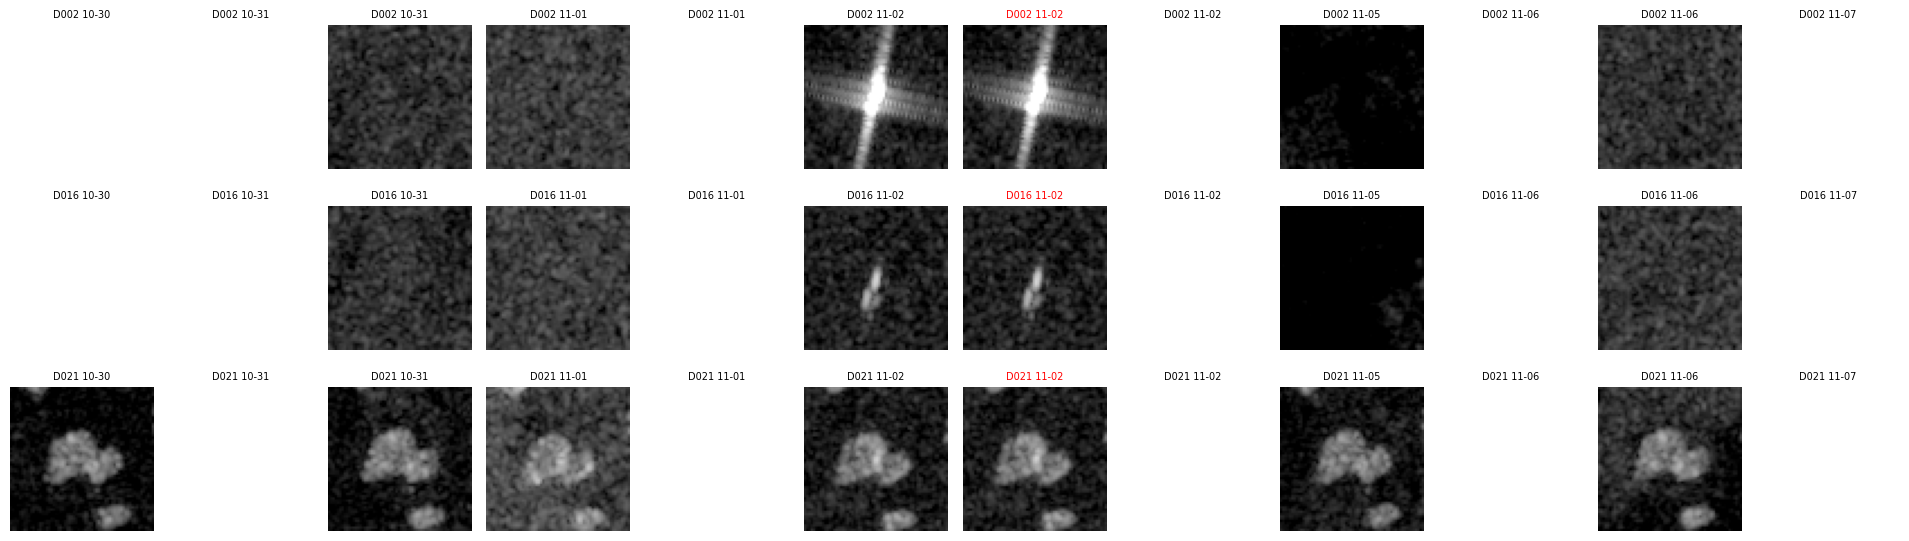

In [23]:
import matplotlib.pyplot as plt
from rasterio.windows import Window

look = [d for d in dets if d['id'] in ('D002', 'D016', 'D021')]
items = sorted(cat.search(collections=['sentinel-1-rtc'], bbox=BBOX,
                          datetime='2026-09-15/2026-11-07', max_items=12).items(),
               key=lambda it: it.datetime)
print(len(items), 'passes:', [it.datetime.strftime('%m-%d') for it in items])

fig, axes = plt.subplots(len(look), len(items), figsize=(1.6 * len(items), 1.9 * len(look)), squeeze=False)
for col, it in enumerate(items):
    with rasterio.open(it.assets['vv'].href) as src:
        for row, d in enumerate(look):
            x, y = warp_transform('EPSG:4326', src.crs, [d['lon']], [d['lat']])
            r, c = rowcol(src.transform, x[0], y[0])
            w = src.read(1, window=Window(c - 32, r - 32, 64, 64), boundless=True, fill_value=0).astype(np.float32)
            dbw = np.where(w > 0, 10 * np.log10(np.maximum(w, 1e-6)), np.nan)
            ax = axes[row, col]; ax.axis('off')
            ax.imshow(dbw, cmap='gray', vmin=-25, vmax=5)
            ax.set_title(f"{d['id']} {it.datetime:%m-%d}", fontsize=7,
                         color='red' if it.id == SCENE else 'black')
plt.tight_layout(); plt.savefig(f'{OUT}/kattegat/persistence.png', dpi=150); plt.show()

In [24]:
import os, json, numpy as np, rasterio, matplotlib.pyplot as plt
from PIL import Image
from rasterio.windows import Window
from google.colab import files

EV = f'{OUT}/evidence'
for sub in ('chips', 'persistence'):
    os.makedirs(f'{EV}/{sub}', exist_ok=True)

# 1) per-detection classifier chips (10 m, brightness-matched), upscaled for display
for d, ch in zip(dets, batch):
    Image.fromarray(ch).resize((256, 256), Image.NEAREST).save(f"{EV}/chips/{d['id']}.png")

# 2) persistence strips: one tile per distinct satellite pass that actually covered the spot
items = list(cat.search(collections=['sentinel-1-rtc'], bbox=BBOX,
                        datetime='2026-09-15/2026-11-07', max_items=12).items())
passes = {}
for it in sorted(items, key=lambda it: it.id != SCENE):          # keep the demo scene's product first
    key = (it.properties.get('platform'), it.properties.get('sat:absolute_orbit'))
    passes.setdefault(key, it)                                     # same pass in 2 products -> one observation
passes = sorted(passes.values(), key=lambda it: it.datetime)

VERDICT = {'D002': 'transient', 'D016': 'transient', 'D021': 'persistent'}   # analyst-reviewed from the grid
persist = {}
for d in [d for d in dets if d['id'] in VERDICT]:
    tiles = []
    for it in passes:
        with rasterio.open(it.assets['vv'].href) as src:
            x, y = warp_transform('EPSG:4326', src.crs, [d['lon']], [d['lat']])
            r, c = rowcol(src.transform, x[0], y[0])
            w = src.read(1, window=Window(c - 32, r - 32, 64, 64), boundless=True, fill_value=0).astype(np.float32)
        ok = (w > 0) & (w != -32768)
        if ok.mean() < 0.5:
            continue                                               # pass did not cover this spot
        tiles.append((it.datetime, it.id == SCENE, np.where(ok, 10 * np.log10(np.maximum(w, 1e-6)), np.nan)))
    fig, axes = plt.subplots(1, len(tiles), figsize=(1.8 * len(tiles), 2.1), squeeze=False, facecolor='#0a0e13')
    for ax, (t, is_scene, dbw) in zip(axes[0], tiles):
        ax.imshow(dbw, cmap='gray', vmin=-25, vmax=5); ax.axis('off')
        ax.set_title(f'{t:%b %d %H:%MZ}', fontsize=8, color='#ff4d4f' if is_scene else '#8a94a3')
    fig.savefig(f"{EV}/persistence/{d['id']}.png", dpi=150, bbox_inches='tight', facecolor='#0a0e13')
    plt.close(fig)
    persist[d['id']] = {'strip': f"persistence/{d['id']}.png", 'verdict': VERDICT[d['id']],
                        'reviewed': 'analyst', 'passes_covering': [t.strftime('%Y-%m-%dT%H:%MZ') for t, _, _ in tiles]}
    print(d['id'], VERDICT[d['id']], len(tiles), 'covering passes')

# 3) evidence.json
ev = {'model': {
        'file': 'ship_clf_single.onnx', 'arch': 'ResNet-18 on 64x64 VV chips at 10 m',
        'train_data': 'LS-SSDD-v1.0: scenes 1-9 train, scene 10 validation, scenes 11-15 test',
        'threshold': T, 'threshold_rule': 'highest threshold keeping >=95% of ships on scene 10',
        'test': {'ap': 0.981, 'ships_kept': 0.968, 'cfar_false_alarms_rejected': 0.886, 'background_rejected': 0.995},
        'kattegat': {'ais_confirmed_recognized': 17, 'ais_confirmed_total': 18,
                     'miss': 'D015 HAGLAND PREMIER, 0.5 km from shore, score 0.63'},
        'license': 'Trained on LS-SSDD-v1.0, which prohibits commercial use'},
      'scene_grid': 'native 10 m UTM (EPSG:32633), Planetary Computer sentinel-1-rtc',
      'detections': {}}
for d, p in zip(dets, probs):
    ev['detections'][d['id']] = {'vessel_score': round(float(p), 4), 'vessel_like': bool(p >= T),
                                 'chip': f"chips/{d['id']}.png"}
for k, v in persist.items():
    ev['detections'][k]['persistence'] = v
json.dump(ev, open(f'{EV}/evidence.json', 'w'), indent=1)

!cd {OUT} && zip -qr evidence.zip evidence && ls -lh evidence.zip
files.download(f'{OUT}/evidence.zip')

D002 transient 5 covering passes
D016 transient 5 covering passes
D021 persistent 6 covering passes
-rw------- 1 root root 471K Nov  8 02:26 evidence.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>